Notebook to examine the effect of EMA sampling on causal models.

In [49]:
import jpype.imports
import os
import platform

# get platform information
uname_info = platform.uname()

if uname_info.node == 'c30-wsacsk4hm3':
    # avd is azure virtual desktop version 

    # set JAVA_HOME
    os.environ['JAVA_HOME'] = "R:/DVBIC/jdk21.0.4_7"
    # check for env JAVA_HOME, this was None
    java_home = os.environ.get('JAVA_HOME')


In [50]:
# setup the jvm
try:
    # works for win11
    jpype.startJVM(classpath=[f"resources/tetrad-current.jar"])
    #jpype.startJVM(classpath=[f"py-tetrad/pytetrad/resources/tetrad-current.jar"])
    
except OSError:
    pass


In [51]:
# define functions
def dice_coefficient(set_a, set_b):
    # Calculate the intersection of the two sets
    intersection = len(set_a.intersection(set_b))
    
    # Calculate the Dice coefficient
    dice = (2 * intersection) / (len(set_a) + len(set_b))
    
    return dice


In [52]:
def extract_edges(text):
    """
    Extract out the edges between Graph Edges and Graph Attributes
    """
    edges = set()
    nodes = set()
    
    # get the lines
    lines = text.split('\n')
    startFlag=False  # True when we are in the edges, False when not
    for line in lines:
        if startFlag == False:
            if "Graph Edges:" in line:
                startFlag = True
                continue  # continue to next line
        if startFlag == True:
            # check if there is edge information a '--'
            if '--' in line:
                # this is an edge so add to the set
                # strip out the number in front  1. drinks --> happy
                # convert to a string
                linestr = str(line)
                clean_edge = linestr.split('. ')[1]
                edges.add(clean_edge)
                pass
    return edges

In [53]:
# create a new method to load df
import tools.translate as tr

def load_df(self,df):
    self.data = tr.pandas_data_to_tetrad(df)

In [54]:
import pandas as pd
import tools.TetradSearch as ts
import tools.translate as tr

NUM_ITERATIONS = 100

# add method to the class
setattr(ts.TetradSearch,'load_df',load_df)

In [55]:
# read in the data file into a pandas df
test_file = "data/sub_1112.csv"
df = pd.read_csv(test_file, sep=",")
df = df.astype({col: "float64" for col in df.columns})

In [56]:
# create the TetradSearch object
search = ts.TetradSearch(df)
    
## Use a SEM BIC score
search.use_sem_bic(penalty_discount=1)

## Set knowledge
search.add_to_tier(0, "lagdrinks")
search.add_to_tier(0, "lagsad")
search.add_to_tier(0, "lagirr")
search.add_to_tier(0, "lagrelax")
search.add_to_tier(0, "laghappy")
search.add_to_tier(0, "lagenerg")
search.add_to_tier(0, "lagstress")
search.add_to_tier(1, "drinks")
search.add_to_tier(1, "sad")
search.add_to_tier(1, "irr")
search.add_to_tier(1, "relax")
search.add_to_tier(1, "happy")
search.add_to_tier(1, "energ")
search.add_to_tier(1, "stress")


[]


In [57]:
# create lists to hold information for creating a df
proportionList = list()
iterationList = list()
diceCoeffList = list()

In [58]:
# loop for the proportion of data to sample

for proportion in [1.0,0.9,0.8,0.7,0.6,0.5,0.4]:
    for iteration in range(NUM_ITERATIONS):
        # resample the dataframe based on proportion
        resampled_df = df.sample(frac=proportion)
        # load the data
        search.load_df(resampled_df)
        
        ## Run the search
        search.run_fges()
        soutput = search.get_string()
        setEdges = extract_edges(soutput)
        if proportion==1.0:
            fullEdges = setEdges.copy()  # full edges from 100%
            
        # calculate the dice coefficient
        diceCoeff = dice_coefficient(fullEdges,setEdges)
        print(f"Proportion: {proportion} Iteration: {iteration+1} diceCoeff: {diceCoeff}")
        
        # load into lists
        proportionList.append(proportion)
        iterationList.append(iteration)
        diceCoeffList.append(diceCoeff)
        pass
    pass

[]


Proportion: 1.0 Iteration: 1 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 2 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 3 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 4 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 5 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 6 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 7 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 8 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 9 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 10 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 11 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 12 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 13 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 14 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 15 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 16 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 17 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 18 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 19 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 20 diceCoeff: 1.0
[]
Proportion: 1.0 Iteration: 21 diceCoeff: 1.0
[]
P

In [36]:
# create dataframe
summaryDf = pd.DataFrame(  {"proportion": proportionList,
                            "iteration": iterationList,
                            "diceCoeff": diceCoeffList
                            }
                        )

# write out to csv
with open("proportion_summary.csv","w") as fp:
    summaryDf.to_csv(fp, index=False)

In [37]:
# create a plot of the distribution of the dice coefficients at different proportions
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



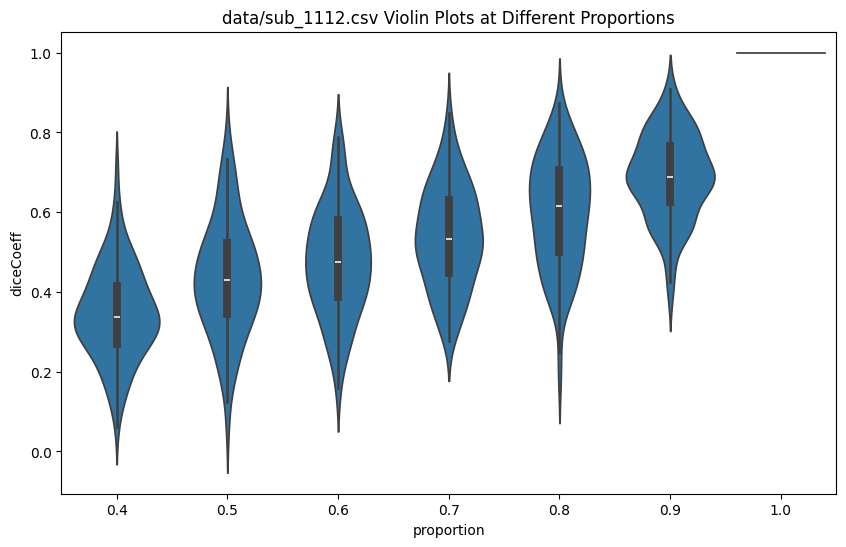

In [38]:
plt.figure(figsize=(10, 6))
sns.violinplot(x='proportion', y='diceCoeff', data=summaryDf)
plt.title(f'{test_file} Violin Plots at Different Proportions')
plt.show()


In [39]:
# now read in multiple files
# read in the data file into a pandas df
import glob

# get the list files in data directory
files = glob.glob("data/*.csv")

files = ["data/sub_1019.csv","data/sub_1033.csv","data/sub_1112.csv"]

In [47]:
# create method to run iterate over different proportions and return
# a df with the results

def run_proportions(df, subj, num_iterations=100, verbose=False):
    """
    Run the proportions for the given df
    """
    # create the TetradSearch object
    search = ts.TetradSearch(df)
    
    ## Use a SEM BIC score
    search.use_sem_bic(penalty_discount=1)

    ## Set knowledge
    search.add_to_tier(0, "lagdrinks")
    search.add_to_tier(0, "lagsad")
    search.add_to_tier(0, "lagirr")
    search.add_to_tier(0, "lagrelax")
    search.add_to_tier(0, "laghappy")
    search.add_to_tier(0, "lagenerg")
    search.add_to_tier(0, "lagstress")
    search.add_to_tier(1, "drinks")
    search.add_to_tier(1, "sad")
    search.add_to_tier(1, "irr")
    search.add_to_tier(1, "relax")
    search.add_to_tier(1, "happy")
    search.add_to_tier(1, "energ")
    search.add_to_tier(1, "stress")


    # create lists to hold information for creating a df
    proportionList = list()
    iterationList = list()
    diceCoeffList = list()
    effectSizeList = list()
    subjList = list()

    # loop for the proportion of data to sample

    for proportion in [1.0,0.9,0.8,0.7,0.6,0.5,0.4]:
        for iteration in range(num_iterations):
            # resample the dataframe based on proportion
            resampled_df = df.sample(frac=proportion)
            # load the data
            search.load_df(resampled_df)

            ## Run the search
            search.run_fges()
            soutput = search.get_string()
            setEdges = extract_edges(soutput)
            
            # run the sem to effect sizes for this model
            
            if proportion==1.0:
                fullEdges = setEdges.copy()  # full edges from 100%

            # calculate the dice coefficient
            diceCoeff = dice_coefficient(fullEdges,setEdges)
            if verbose: print(f"Proportion: {proportion} Iteration: {iteration+1} diceCoeff: {diceCoeff}")

            # load into lists
            proportionList.append(proportion)
            iterationList.append(iteration)
            diceCoeffList.append(diceCoeff)
            subjList.append(subj)
            pass
        pass

    # create dataframe
    df = pd.DataFrame(  {"case": subjList,
                                "proportion": proportionList,
                                "iteration": iterationList,
                                "diceCoeff": diceCoeffList
                            }
                        )
    return df

In [48]:
# iterate over the files
from pathlib import Path

dfSummary = None

for file in files:
    # get subject number
    subj = Path(file).stem.split('_')[1]
    print(subj, file)
    df_raw = pd.read_csv(file, sep=",")
    df_raw = df.astype({col: "float64" for col in df.columns})
    

    df = run_proportions(df_raw, subj)
    if dfSummary is None:
        dfSummary = df.copy()
    else:
        dfSummary = pd.concat([dfSummary,df],ignore_index=True)


1019 data/sub_1019.csv


[]
[]
Singularity encountered when scoring proportion | case
Singularity encountered when scoring proportion | case, diceCoeff
Singularity encountered when scoring iteration | case
Singularity encountered when scoring diceCoeff | case
Singularity encountered when scoring diceCoeff | case, proportion
[]
Singularity encountered when scoring proportion | case
Singularity encountered when scoring proportion | case, diceCoeff
Singularity encountered when scoring iteration | case
Singularity encountered when scoring diceCoeff | case
Singularity encountered when scoring diceCoeff | case, proportion
[]
Singularity encountered when scoring proportion | case
Singularity encountered when scoring proportion | case, diceCoeff
Singularity encountered when scoring iteration | case
Singularity encountered when scoring diceCoeff | case
Singularity encountered when scoring diceCoeff | case, proportion
[]
Singularity encountered when scoring proportion | case
Singularity encountered when scoring proporti

In [42]:
len(dfSummary)

2100

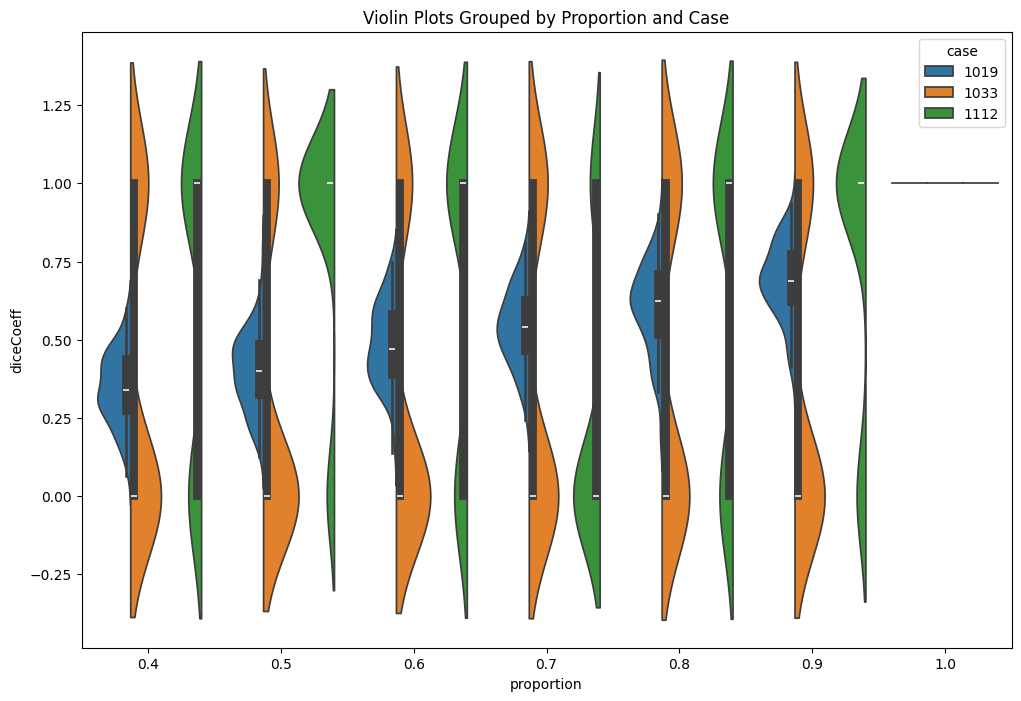

In [43]:
plt.figure(figsize=(12, 8))
sns.violinplot(x='proportion', y='diceCoeff', hue='case', data=dfSummary, split=True)
plt.title('Violin Plots Grouped by Proportion and Case')
plt.show()
